### Step 1 – Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

### Step 2 – Load the Required Datasets

In [2]:
orders = pd.read_csv("../datasets/olist_orders_dataset.csv")

payments = pd.read_csv("../datasets/olist_order_payments_dataset.csv")

print("Orders Shape:", orders.shape)
print("Payments Shape:", payments.shape)

print("\nOrders Dataset:")
display(orders.head())

print("\nPayments Dataset:")
display(payments.head())

Orders Shape: (99441, 8)
Payments Shape: (103886, 5)

Orders Dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Payments Dataset:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### Step 3 – Convert Date and Calculate Monthly Revenue

In [3]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

monthly_payments = payments.groupby("order_id", as_index=False).agg(
    Monthly_Order_Revenue=("payment_value", "sum")
)

orders_revenue = orders.merge(
    monthly_payments,
    on="order_id",
    how="inner"
)

# Consider only delivered orders
delivered_orders = orders_revenue[
    orders_revenue["order_status"] == "delivered"
].copy()

delivered_orders["Year_Month"] = (
    delivered_orders["order_purchase_timestamp"].dt.to_period("M")
)

monthly_revenue = delivered_orders.groupby(
    "Year_Month"
)["Monthly_Order_Revenue"].sum().reset_index()

monthly_revenue["Year_Month"] = (
    monthly_revenue["Year_Month"].dt.to_timestamp()
)

print(monthly_revenue.head())
print("\nTotal Months:", len(monthly_revenue))

  Year_Month  Monthly_Order_Revenue
0 2016-10-01               46566.71
1 2016-12-01                  19.62
2 2017-01-01              127545.67
3 2017-02-01              271298.65
4 2017-03-01              414369.39

Total Months: 22


### Step 4 – Complete the Monthly Revenue Timeline

In [4]:
monthly_revenue = monthly_revenue.set_index("Year_Month")

monthly_revenue = monthly_revenue.asfreq("MS", fill_value=0)

monthly_revenue = monthly_revenue.reset_index()

print("Total Months:", len(monthly_revenue))

print(monthly_revenue)

Total Months: 23
   Year_Month  Monthly_Order_Revenue
0  2016-10-01               46566.71
1  2016-11-01                   0.00
2  2016-12-01                  19.62
3  2017-01-01              127545.67
4  2017-02-01              271298.65
5  2017-03-01              414369.39
6  2017-04-01              390952.18
7  2017-05-01              567066.73
8  2017-06-01              490225.60
9  2017-07-01              566403.93
10 2017-08-01              646000.61
11 2017-09-01              701169.99
12 2017-10-01              751140.27
13 2017-11-01             1153528.05
14 2017-12-01              843199.17
15 2018-01-01             1078606.86
16 2018-02-01              966510.88
17 2018-03-01             1120678.00
18 2018-04-01             1132933.95
19 2018-05-01             1128836.69
20 2018-06-01             1012090.68
21 2018-07-01             1027903.86
22 2018-08-01              985414.28


### Step 5 – Visualize Monthly Revenue Trends

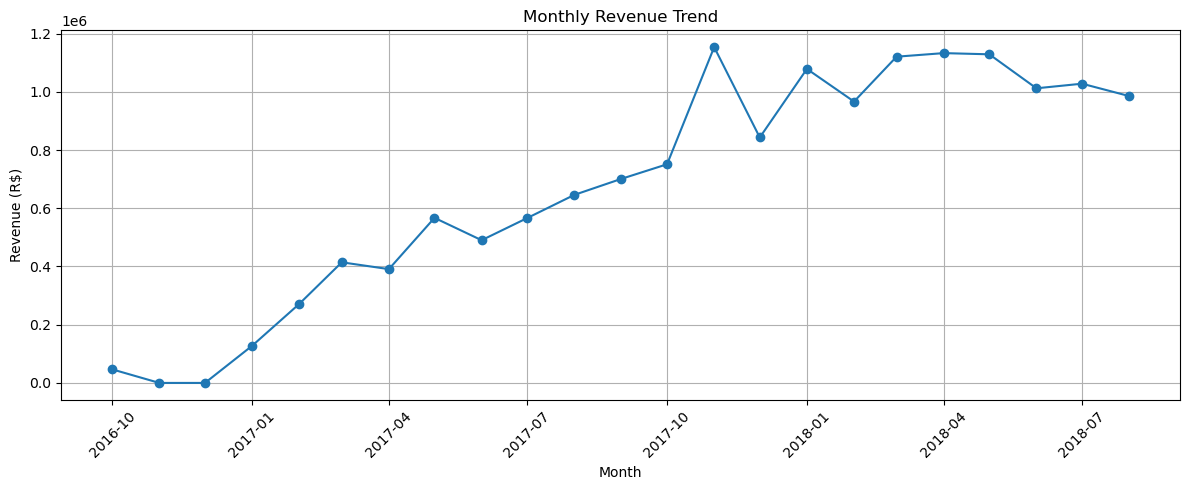

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["Year_Month"],
    monthly_revenue["Monthly_Order_Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 6 – Create Time-Based Features

In [6]:
monthly_revenue["Year"] = monthly_revenue["Year_Month"].dt.year
monthly_revenue["Month"] = monthly_revenue["Year_Month"].dt.month

monthly_revenue["Previous_Month_Revenue"] = (
    monthly_revenue["Monthly_Order_Revenue"].shift(1)
)

monthly_revenue["Previous_2_Month_Revenue"] = (
    monthly_revenue["Monthly_Order_Revenue"].shift(2)
)

monthly_revenue["Previous_3_Month_Revenue"] = (
    monthly_revenue["Monthly_Order_Revenue"].shift(3)
)

monthly_revenue.head(10)

,Year_Month,Monthly_Order_Revenue,Year,Month,Previous_Month_Revenue,Previous_2_Month_Revenue,Previous_3_Month_Revenue
0,2016-10-01,46566.71,2016,10,NaN,NaN,NaN
1,2016-11-01,0.00,2016,11,46566.71,NaN,NaN
2,2016-12-01,19.62,2016,12,0.00,46566.71,NaN
3,2017-01-01,127545.67,2017,1,19.62,0.00,46566.71
4,2017-02-01,271298.65,2017,2,127545.67,19.62,0.00
5,2017-03-01,414369.39,2017,3,271298.65,127545.67,19.62
6,2017-04-01,390952.18,2017,4,414369.39,271298.65,127545.67
7,2017-05-01,567066.73,2017,5,390952.18,414369.39,271298.65
8,2017-06-01,490225.60,2017,6,567066.73,390952.18,414369.39
9,2017-07-01,566403.93,2017,7,490225.60,567066.73,390952.18


### Step 7 – Remove Rows with Missing Lag Values

In [7]:
monthly_revenue = monthly_revenue.dropna().reset_index(drop=True)

print("Dataset Shape:", monthly_revenue.shape)

print("\nMissing Values:")
print(monthly_revenue.isnull().sum())

monthly_revenue.head()

Dataset Shape: (20, 7)

Missing Values:
Year_Month                  0
Monthly_Order_Revenue       0
Year                        0
Month                       0
Previous_Month_Revenue      0
Previous_2_Month_Revenue    0
Previous_3_Month_Revenue    0
dtype: int64


,Year_Month,Monthly_Order_Revenue,Year,Month,Previous_Month_Revenue,Previous_2_Month_Revenue,Previous_3_Month_Revenue
0,2017-01-01,127545.67,2017,1,19.62,0.00,46566.71
1,2017-02-01,271298.65,2017,2,127545.67,19.62,0.00
2,2017-03-01,414369.39,2017,3,271298.65,127545.67,19.62
3,2017-04-01,390952.18,2017,4,414369.39,271298.65,127545.67
4,2017-05-01,567066.73,2017,5,390952.18,414369.39,271298.65


### Step 8 – Prepare Training and Testing Data

In [8]:
features = [
    "Year",
    "Month",
    "Previous_Month_Revenue",
    "Previous_2_Month_Revenue",
    "Previous_3_Month_Revenue"
]

X = monthly_revenue[features]
y = monthly_revenue["Monthly_Order_Revenue"]

split_index = int(len(monthly_revenue) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Period:")
print(monthly_revenue["Year_Month"].iloc[:split_index])

print("\nTesting Period:")
print(monthly_revenue["Year_Month"].iloc[split_index:])

Training Data Shape: (16, 5)
Testing Data Shape: (4, 5)

Training Period:
0    2017-01-01
1    2017-02-01
2    2017-03-01
3    2017-04-01
4    2017-05-01
5    2017-06-01
6    2017-07-01
7    2017-08-01
8    2017-09-01
9    2017-10-01
10   2017-11-01
11   2017-12-01
12   2018-01-01
13   2018-02-01
14   2018-03-01
15   2018-04-01
Name: Year_Month, dtype: datetime64[ns]

Testing Period:
16   2018-05-01
17   2018-06-01
18   2018-07-01
19   2018-08-01
Name: Year_Month, dtype: datetime64[ns]


### Step 9 – Train the Random Forest Regression Model

In [9]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Revenue Prediction Model Trained Successfully!")

Revenue Prediction Model Trained Successfully!


### Step 10 – Predict Monthly Revenue

In [10]:
y_pred = rf_model.predict(X_test)

results = pd.DataFrame({
    "Actual_Revenue": y_test.values,
    "Predicted_Revenue": y_pred.round(2)
})

print(results)

   Actual_Revenue  Predicted_Revenue
0      1128836.69         1068980.94
1      1012090.68         1036533.04
2      1027903.86         1036353.46
3       985414.28         1027272.44


### Step 11 – Evaluate Revenue Prediction Performance

In [11]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 33651.47
Root Mean Squared Error (RMSE): 38741.58
R2 Score: 0.4907


### Step 12 – Visualize Actual vs Predicted Revenue

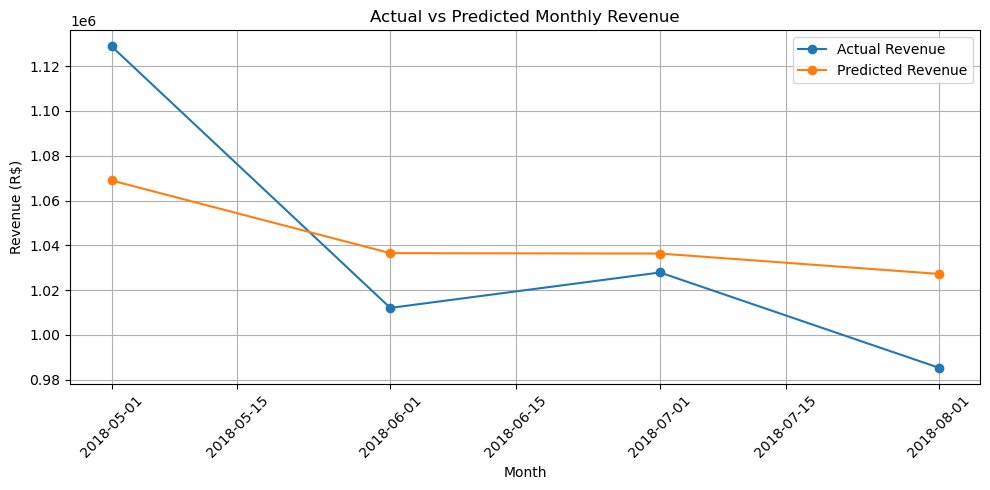

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue["Year_Month"].iloc[split_index:],
    y_test.values,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    monthly_revenue["Year_Month"].iloc[split_index:],
    y_pred,
    marker="o",
    label="Predicted Revenue"
)

plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 13 – Export Revenue Predictions

In [14]:
revenue_results = pd.DataFrame({
    "Year_Month": monthly_revenue["Year_Month"].iloc[split_index:].values,
    "Actual_Revenue": y_test.values,
    "Predicted_Revenue": y_pred.round(2)
})

revenue_results.to_csv(
    "monthly_revenue_predictions.csv",
    index=False
)

print("Revenue predictions exported successfully!")

revenue_results

Revenue predictions exported successfully!


,Year_Month,Actual_Revenue,Predicted_Revenue
0,2018-05-01,1128836.69,1068980.94
1,2018-06-01,1012090.68,1036533.04
2,2018-07-01,1027903.86,1036353.46
3,2018-08-01,985414.28,1027272.44


In [15]:
import pandas as pd

orders_test = pd.read_csv(
    r"C:\Users\Sinchan\Downloads\AI_Customer_Intelligence\datasets\olist_orders_dataset.csv"
)

print("Shape:", orders_test.shape)
print(orders_test.head())

Shape: (99441, 8)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00

In [16]:
with open(
    r"C:\Users\Sinchan\Downloads\AI_Customer_Intelligence\datasets\olist_orders_dataset.csv",
    "rb"
) as file:
    print(file.readline())

b'"order_id","customer_id","order_status","order_purchase_timestamp","order_approved_at","order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date"\n'
